In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

In [9]:
df = pd.read_csv("../data/diabetes.csv")
print(df.shape)
df.head()

(768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [10]:
cols_with_invalid_zero = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
for col in cols_with_invalid_zero:
    df[col] = df[col].replace(0, np.nan)
    df[col] = df[col].fillna(df[col].median())
df.isnull().sum()


Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

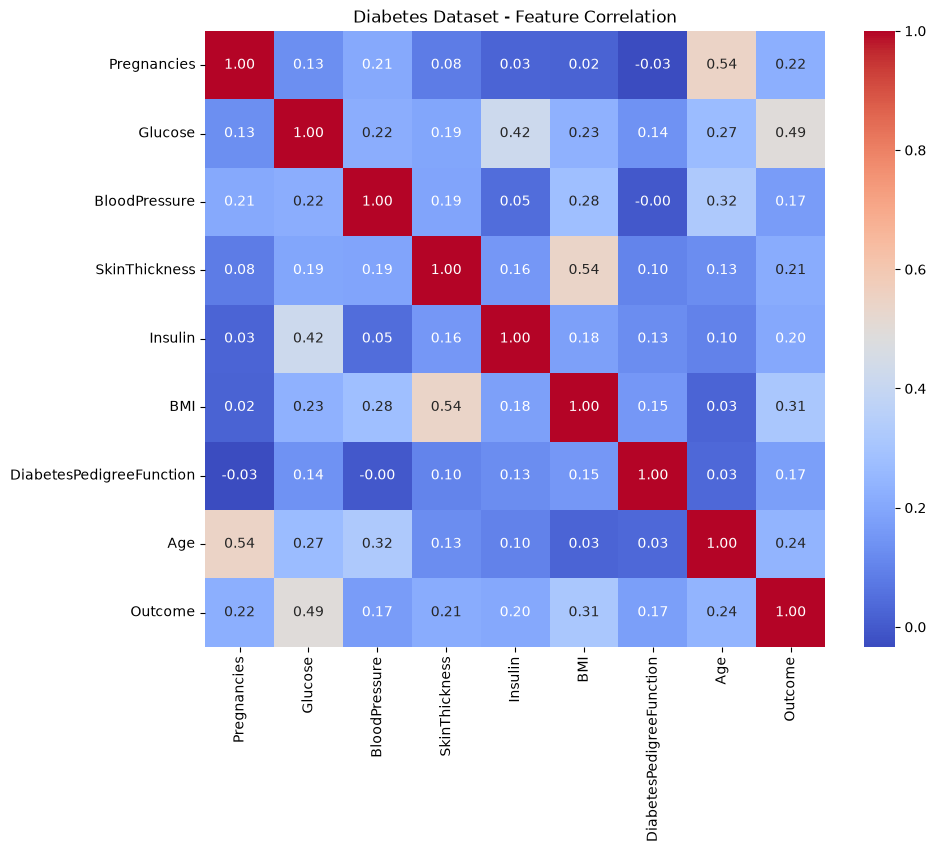

In [11]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Diabetes Dataset - Feature Correlation")
plt.show()

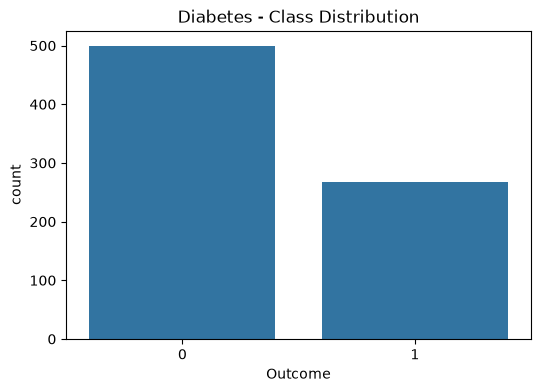

In [12]:
plt.figure(figsize=(6, 4))
sns.countplot(x="Outcome", data=df)
plt.title("Diabetes - Class Distribution")
plt.show()

In [13]:
X = df.drop("Outcome", axis=1)
y = df["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [16]:
param_grid = {
    "C": [0.1, 1, 5, 10, 50, 100, 500],
    "gamma": ["scale", "auto", 0.1, 0.01, 0.001, 0.0001],
    "kernel": ["rbf"]
}
grid = GridSearchCV(SVC(probability=True, class_weight="balanced"), param_grid, cv=5, scoring="accuracy", n_jobs=-1)
grid.fit(X_train_scaled, y_train)

best_model = grid.best_estimator_
print("Best Params:", grid.best_params_)

C:\Users\lahar\OneDrive\Desktop\Multi Disease prediction\venv\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Best Params: {'C': 500, 'gamma': 0.01, 'kernel': 'rbf'}


Accuracy: 0.7403
              precision    recall  f1-score   support

           0       0.81      0.78      0.80       100
           1       0.62      0.67      0.64        54

    accuracy                           0.74       154
   macro avg       0.72      0.72      0.72       154
weighted avg       0.75      0.74      0.74       154



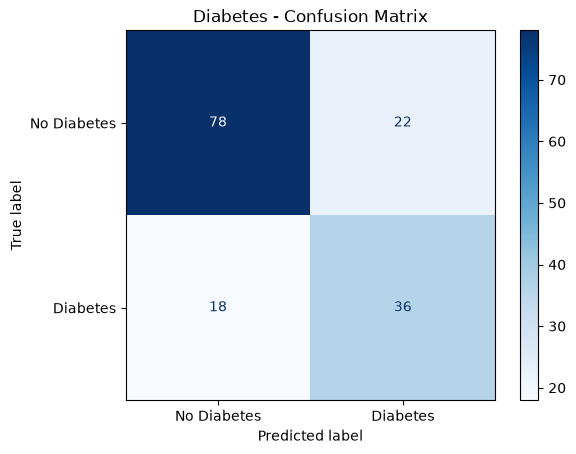

In [17]:
y_pred = best_model.predict(X_test_scaled)
acc = accuracy_score(y_test, y_pred)
print(f"Accuracy: {acc:.4f}")
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No Diabetes", "Diabetes"])
disp.plot(cmap="Blues")
plt.title("Diabetes - Confusion Matrix")
plt.show()

In [18]:
with open("../models/diabetes_model.pkl", "wb") as f:
    pickle.dump(best_model, f)
with open("../models/diabetes_scaler.pkl", "wb") as f:
    pickle.dump(scaler, f)
with open("../models/diabetes_metrics.pkl", "wb") as f:
    pickle.dump({"accuracy": acc, "best_params": grid.best_params_}, f)

print("Saved diabetes model, scaler, metrics.")

Saved diabetes model, scaler, metrics.
